# SMS Spam Classification (Improved Version)
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

**What is new compared to the first version**
- Hand-made features (length, digits, capital letters, `!`, currency symbols, URLs, phone-like numbers)
- Word TF-IDF + character TF-IDF + numeric features combined in one pipeline
- Class imbalance handling with `class_weight='balanced'`
- Four models compared with stratified 5-fold cross-validation
- Grid search on the best model
- Baseline (old model) vs improved model on the same test set
- ROC curve, Precision-Recall curve, confusion matrix, error analysis, top spam / ham words
- Probability output with calibration, model saving, and an interactive prediction function

In [1]:
!pip -q install wordcloud nltk scikit-learn seaborn joblib

In [2]:
import os, re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

## 1. Load Dataset
Place the Kaggle `spam.csv` next to the notebook. On Google Colab you will be asked to upload it.

In [3]:
FILE = next((f for f in ['spam.csv', 'SMS.csv', 'sms.csv'] if os.path.exists(f)), None)

if FILE is None:
    try:
        from google.colab import files
        FILE = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError('Put spam.csv in the same folder as this notebook.')

df = pd.read_csv(FILE, encoding='latin-1')[['v1', 'v2']]
df.columns = ['label', 'message']

print(df.shape)
print(df.isnull().sum())
print('Duplicates:', df.duplicated().sum())
print(df['label'].value_counts())

Saving SMS.csv to SMS.csv
(5572, 2)
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})
print(df.shape)
print(df['label'].value_counts(normalize=True).round(3))

(5169, 3)
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64


## 2. Feature Engineering

In [5]:
stop_words = set(stopwords.words('english'))
lemm = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' url ', text)
    text = re.sub(r'\S+@\S+', ' email ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    return ' '.join(lemm.lemmatize(w) for w in text.split() if w not in stop_words)

NUM_COLS = ['char_count', 'word_count', 'digit_count', 'upper_ratio',
            'exclaim_count', 'currency_count', 'has_url', 'has_phone']

def make_frame(messages):
    s = pd.Series(list(messages)).astype(str)
    f = pd.DataFrame({'message': s})
    f['clean_message'] = s.apply(clean_text)
    f['char_count'] = s.str.len()
    f['word_count'] = s.str.split().str.len()
    f['digit_count'] = s.str.count(r'\d')
    f['upper_ratio'] = s.apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1))
    f['exclaim_count'] = s.str.count('!')
    f['currency_count'] = s.str.count(r'[£$€]')
    f['has_url'] = s.str.contains(r'http\S+|www\S+', case=False).astype(int)
    f['has_phone'] = s.str.contains(r'\d{5,}').astype(int)
    return f

data = make_frame(df['message'])
data['target'] = df['target'].values
data.head()

,message,clean_message,char_count,word_count,digit_count,upper_ratio,exclaim_count,currency_count,has_url,has_phone,target
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,111,20,0,0.027027,0,0,0,0,0
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,29,6,0,0.068966,0,0,0,0,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,155,28,25,0.064516,0,0,0,1,1
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say,49,11,0,0.040816,0,0,0,0,0
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though,61,13,0,0.032787,0,0,0,0,0


## 3. Exploratory Data Analysis

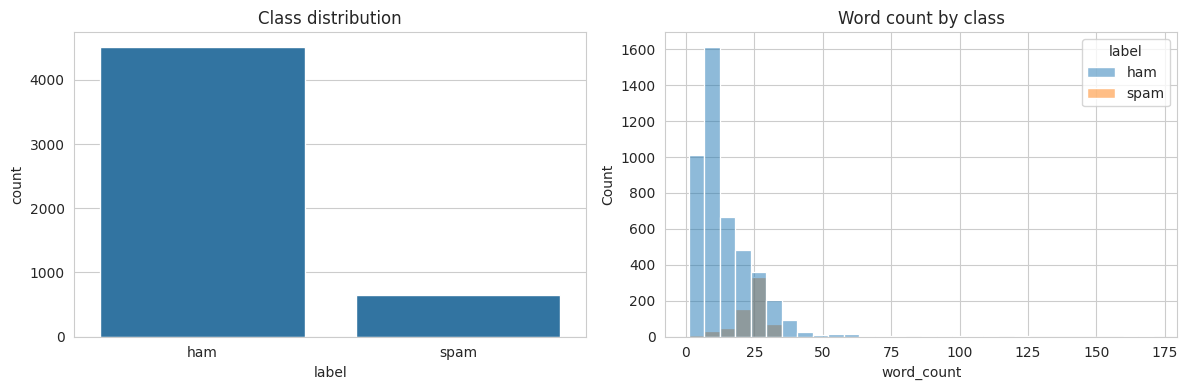

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df['label'], ax=ax[0])
ax[0].set_title('Class distribution')
sns.histplot(data=data.assign(label=df['label']), x='word_count', hue='label', bins=30, ax=ax[1])
ax[1].set_title('Word count by class')
plt.tight_layout()
plt.show()

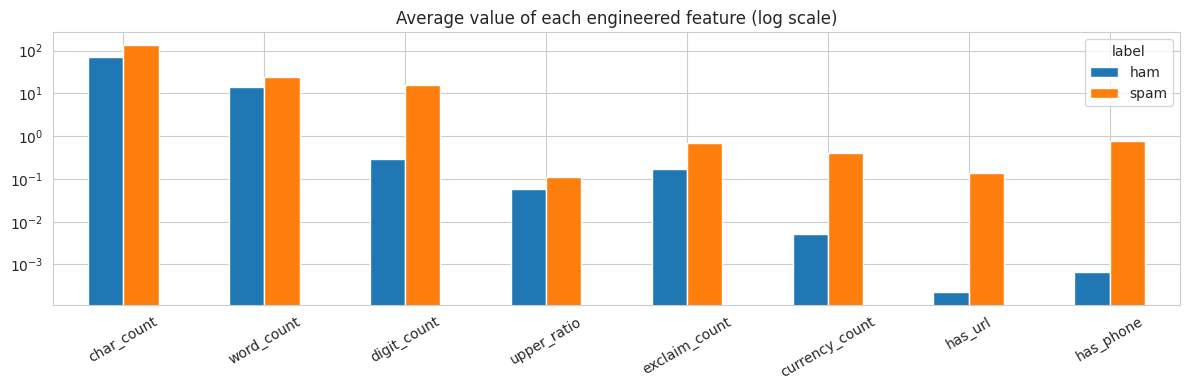

label,ham,spam
char_count,70.459,137.891
word_count,14.135,23.681
digit_count,0.290,15.447
upper_ratio,0.058,0.110
exclaim_count,0.175,0.694
currency_count,0.005,0.415
has_url,0.000,0.139
has_phone,0.001,0.766


In [7]:
summary = data.groupby(df['label'])[NUM_COLS].mean().T
summary.plot(kind='bar', figsize=(12, 4), logy=True)
plt.title('Average value of each engineered feature (log scale)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
summary.round(3)

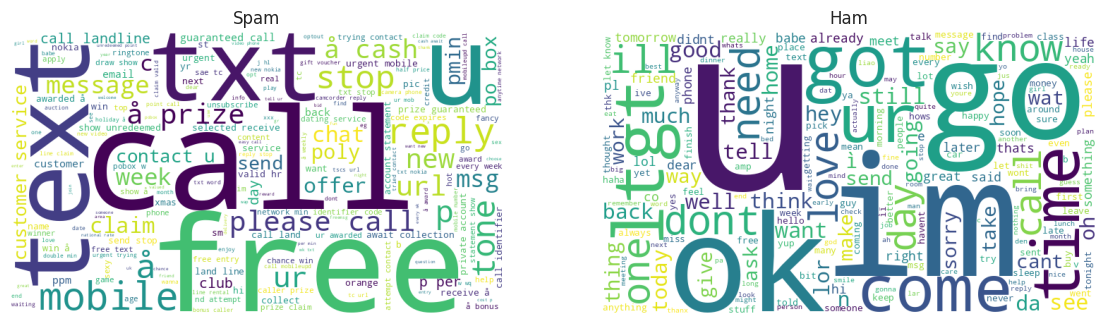

In [8]:
spam_text = ' '.join(data.loc[data.target == 1, 'clean_message'])
ham_text = ' '.join(data.loc[data.target == 0, 'clean_message'])

plt.figure(figsize=(14, 5))
for i, (txt, name) in enumerate([(spam_text, 'Spam'), (ham_text, 'Ham')], 1):
    plt.subplot(1, 2, i)
    plt.imshow(WordCloud(background_color='white', width=700, height=400).generate(txt))
    plt.axis('off')
    plt.title(name)
plt.show()

## 4. Train / Test Split

In [9]:
X = data.drop(columns='target')
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)
print('Spam share in train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

(4135, 10) (1034, 10)
Spam share in train: 0.126 | test: 0.127


## 5. Baseline (Original Model)
The first version: word TF-IDF (5000 features) + default `LinearSVC`, used as the reference point.

In [10]:
def report(name, y_true, y_pred):
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC())
])
baseline.fit(X_train['clean_message'], y_train)
baseline_pred = baseline.predict(X_test['clean_message'])
baseline_result = report('Baseline (old)', y_test, baseline_pred)
pd.DataFrame([baseline_result]).round(4)

,model,accuracy,precision,recall,f1
0,Baseline (old),0.9836,0.9831,0.8855,0.9317


## 6. Improved Pipeline: Word TF-IDF + Character TF-IDF + Numeric Features

In [11]:
def build_preprocessor():
    return ColumnTransformer([
        ('word', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), 'clean_message'),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3,
                                 sublinear_tf=True, lowercase=False), 'message'),
        ('num', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', MaxAbsScaler())]), NUM_COLS),
    ])

models = {
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=RANDOM_STATE),
    'LogisticRegression': LogisticRegression(class_weight='balanced', max_iter=3000,
                                             random_state=RANDOM_STATE),
    'SGD (modified huber)': SGDClassifier(loss='modified_huber', class_weight='balanced',
                                          random_state=RANDOM_STATE),
    'ComplementNB': ComplementNB(),
}

def make_pipeline(model):
    return Pipeline([('prep', build_preprocessor()), ('clf', model)])

## 7. Model Comparison (Stratified 5-Fold Cross-Validation on Training Data)

,accuracy,precision,recall,f1
model,,,,
SGD (modified huber),0.9898,0.9802,0.9386,0.9588
LinearSVC,0.9898,0.9839,0.9348,0.9587
LogisticRegression,0.9872,0.9643,0.9329,0.9482
ComplementNB,0.9821,0.9472,0.9099,0.9280


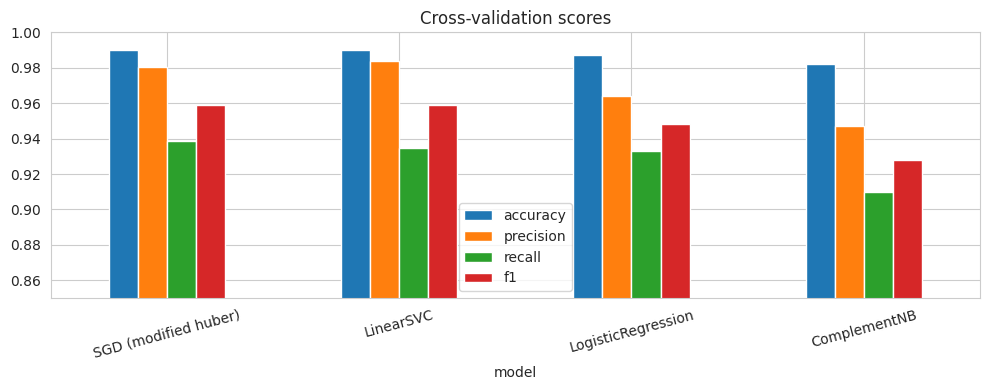

Best model by F1: SGD (modified huber)


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1']

rows = []
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'model': name, **{m: res['test_' + m].mean() for m in scoring}})

cv_table = pd.DataFrame(rows).set_index('model').sort_values('f1', ascending=False)
display(cv_table.round(4))

cv_table.plot(kind='bar', figsize=(10, 4), ylim=(0.85, 1.0))
plt.title('Cross-validation scores')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_name = cv_table.index[0]
print('Best model by F1:', best_name)

## 8. Hyperparameter Tuning (Best Model)

In [ ]:
param_grids = {
    'LinearSVC': {'clf__C': [0.1, 0.3, 1, 3, 10]},
    'LogisticRegression': {'clf__C': [1, 3, 10, 30, 100]},
    'SGD (modified huber)': {'clf__alpha': [1e-6, 1e-5, 1e-4, 1e-3]},
    'ComplementNB': {'clf__alpha': [0.01, 0.1, 0.5, 1.0]},
}

grid = GridSearchCV(make_pipeline(models[best_name]), param_grids[best_name],
                    cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV F1:', round(grid.best_score_, 4))
best_model = grid.best_estimator_

## 9. Final Evaluation on the Test Set

In [ ]:
def get_scores(model, X):
    if hasattr(model, 'decision_function'):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]

pred = best_model.predict(X_test)
scores = get_scores(best_model, X_test)

improved_result = report('Improved (new)', y_test, pred)
comparison = pd.DataFrame([baseline_result, improved_result]).set_index('model')
display(comparison.round(4))
print(classification_report(y_test, pred, target_names=['ham', 'spam']))
print('ROC AUC:', round(roc_auc_score(y_test, scores), 4))
print('Average Precision:', round(average_precision_score(y_test, scores), 4))

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['ham', 'spam']).plot(
    ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')

fpr, tpr, _ = roc_curve(y_test, scores)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, scores):.4f}')
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False positive rate')
ax[1].set_ylabel('True positive rate')
ax[1].set_title('ROC curve')
ax[1].legend()

p, r, _ = precision_recall_curve(y_test, scores)
ax[2].plot(r, p, label=f'AP = {average_precision_score(y_test, scores):.4f}')
ax[2].set_xlabel('Recall')
ax[2].set_ylabel('Precision')
ax[2].set_title('Precision-Recall curve')
ax[2].legend()

plt.tight_layout()
plt.show()

## 10. Error Analysis

In [ ]:
errors = X_test[['message']].copy()
errors['actual'] = y_test.map({0: 'ham', 1: 'spam'})
errors['predicted'] = pd.Series(pred, index=y_test.index).map({0: 'ham', 1: 'spam'})
errors = errors[errors.actual != errors.predicted]

pd.set_option('display.max_colwidth', 150)
print('Total mistakes:', len(errors))
errors

## 11. Most Important Words and Features

In [ ]:
clf = best_model.named_steps['clf']

if hasattr(clf, 'coef_'):
    names = best_model.named_steps['prep'].get_feature_names_out()
    names = np.array([n.split('__', 1)[1] for n in names])
    coefs = clf.coef_.ravel()
    order = np.argsort(coefs)

    top_spam = pd.Series(coefs[order[-20:]], index=names[order[-20:]])
    top_ham = pd.Series(coefs[order[:20]], index=names[order[:20]])

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    top_spam.plot(kind='barh', ax=ax[0], color='crimson')
    ax[0].set_title('Strongest spam indicators')
    top_ham.plot(kind='barh', ax=ax[1], color='seagreen')
    ax[1].set_title('Strongest ham indicators')
    plt.tight_layout()
    plt.show()
else:
    print('This model has no coefficients to display.')

## 12. Calibrated Final Model (Gives Spam Probability)

In [ ]:
final_model = CalibratedClassifierCV(
    make_pipeline(models[best_name]).set_params(**grid.best_params_), cv=5
)
final_model.fit(X_train, y_train)

proba = final_model.predict_proba(X_test)[:, 1]
final_pred = (proba >= 0.5).astype(int)
print('Calibrated model results')
print(pd.DataFrame([report('Calibrated', y_test, final_pred)]).round(4).to_string(index=False))

## 13. Save Model and Predict New Messages

In [ ]:
joblib.dump(final_model, 'spam_model.joblib')

def predict_sms(text, threshold=0.5):
    p = final_model.predict_proba(make_frame([text]))[0, 1]
    return {'label': 'Spam' if p >= threshold else 'Ham', 'spam_probability': round(float(p), 4)}

tests = [
    'Congratulations! You have won a free iPhone. Click here now.',
    'Hi, are we meeting tomorrow at 3 PM?',
    'URGENT! Your mobile number has won a 2000 pound prize. Call 09061701461 to claim.',
    'Can you send me the notes from the class today?',
    'FREE entry in a weekly comp! Text WIN to 80086 now to receive your prize.',
]
pd.DataFrame([{'message': t, **predict_sms(t)} for t in tests])